# EDA: MOEX Portfolio Copilot

Исследуется только development 2015–2024. Источники и хеши сырых ответов хранятся в `reports/eda/sources_manifest.json`; сырьё не публикуется. Квартальные составы индекса задают диагностическую панель. Этот ноутбук не является бэктестом и не оценивает прибыльность стратегии.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from moex_portfolio.eda import build_report  # noqa: E402

summary = build_report(
    ROOT / "data/processed", ROOT / "reports/eda", config_path=ROOT / "configs/eda.json"
)
display(pd.DataFrame(summary["tables"]).T)

,rows,columns,processed_bytes
candles,166782,9,5138811
index_snapshots,1803,9,17725
history,1767,24,150701
benchmark,2508,20,138846
fx,2468,3,36816
key_rate,2504,2,15667
news,91477,8,41610503


## Состав и качество рыночных данных

В панели 89 тикеров и 166,782 свечей. Разная длина истории отражает и листинги/корпоративные события, и ограничения выбранного режима торгов. Отсутствие на дате MCFTR — диагностический флаг; его нельзя автоматически заполнять предыдущей ценой.

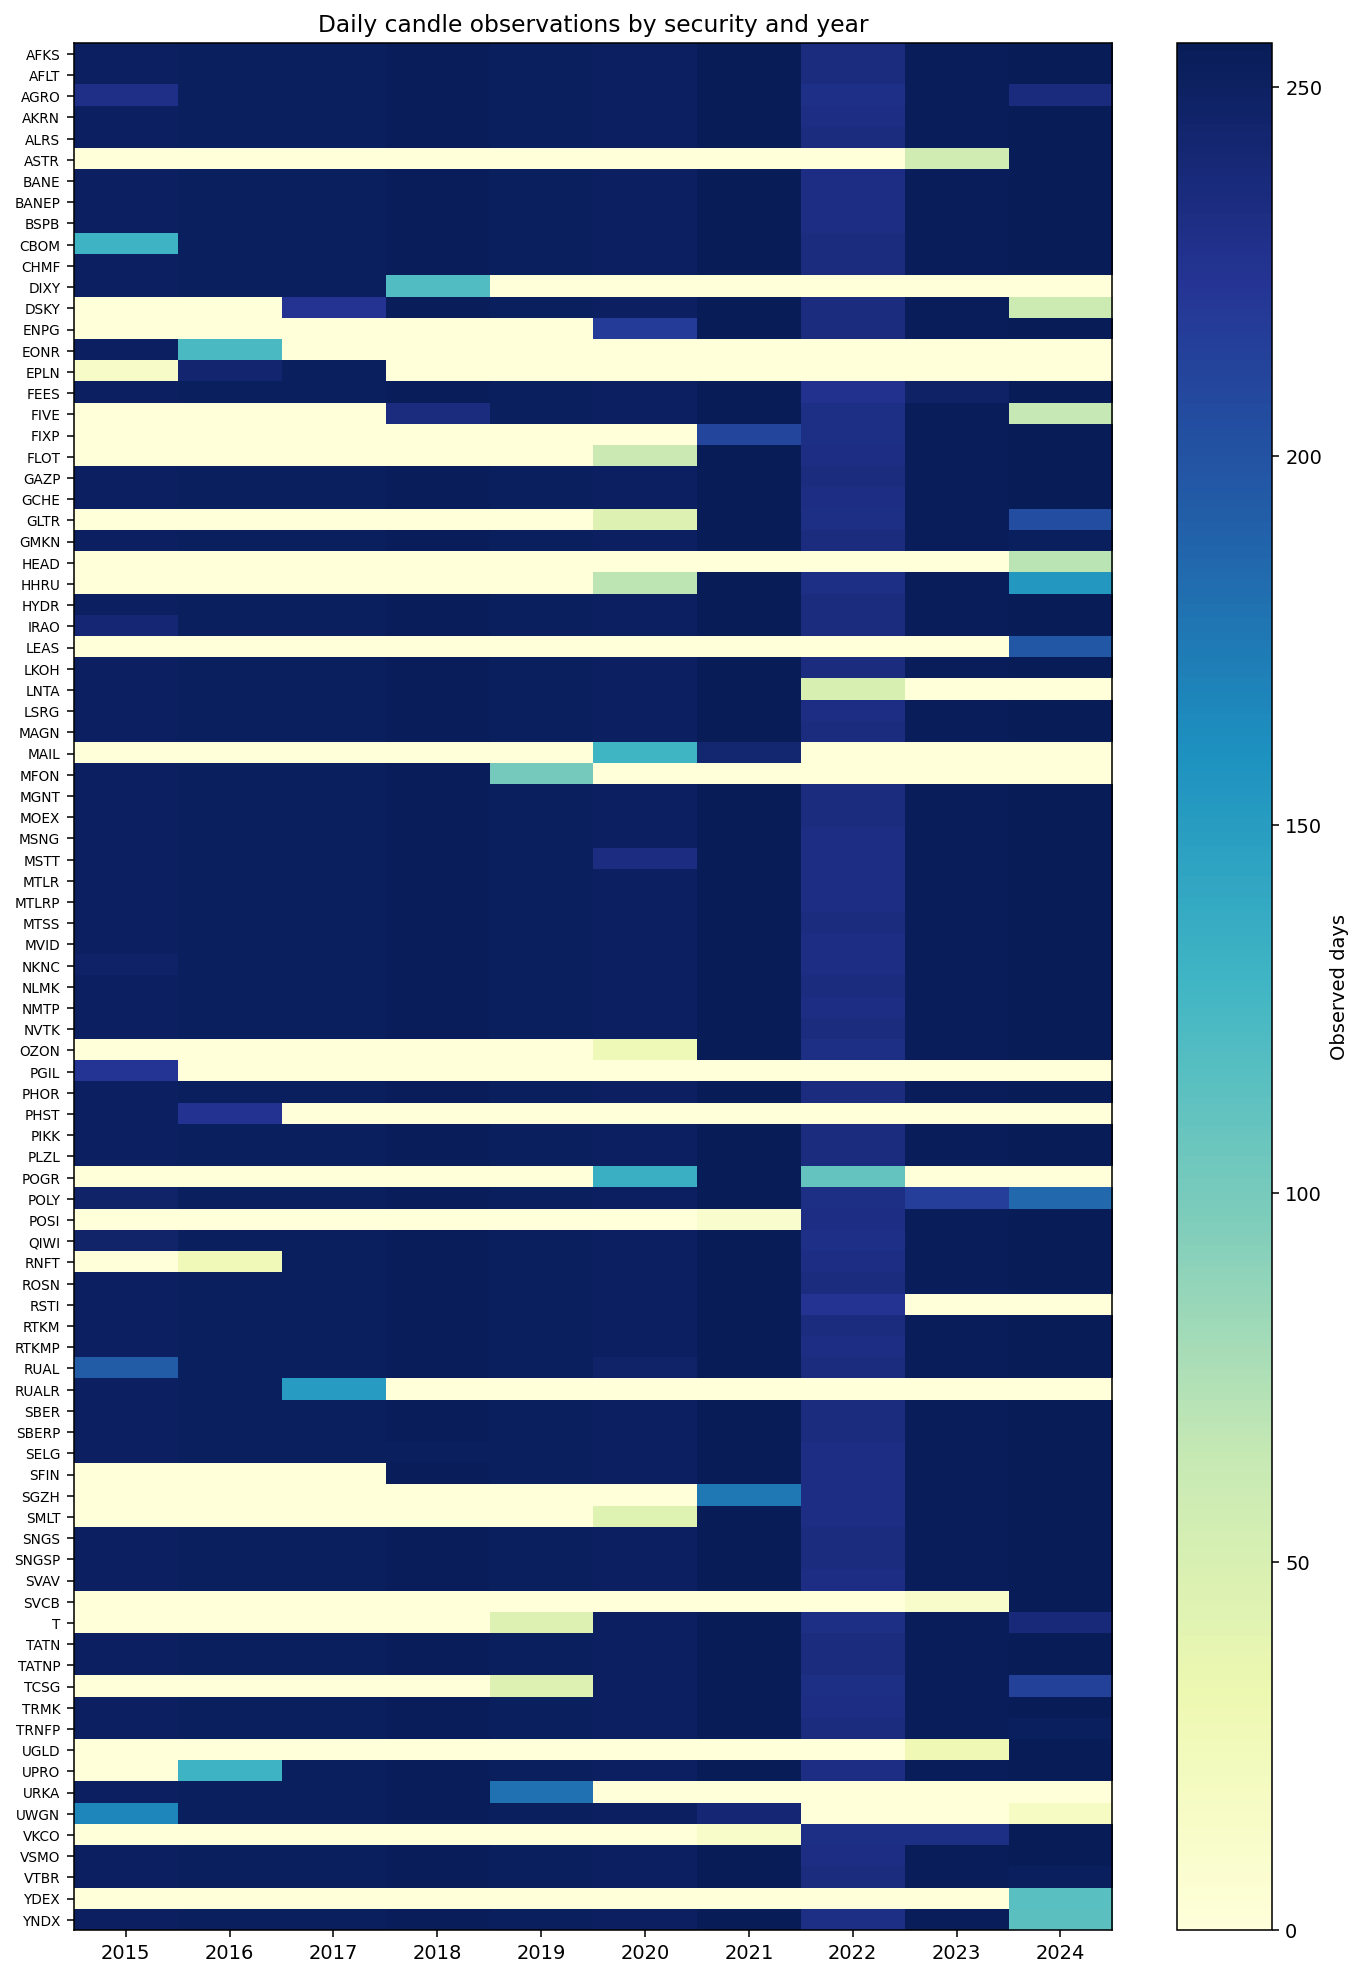

,secid,rows,first_date,last_date,benchmark_dates_within_span,absent_on_benchmark_date,zero_volume_rows
0,AFKS,2509,2015-01-05,2024-12-30,2508,0,0
1,AFLT,2509,2015-01-05,2024-12-30,2508,0,0
2,AGRO,2463,2015-01-05,2024-12-02,2487,24,0
3,AKRN,2507,2015-01-05,2024-12-30,2508,1,0
4,ALRS,2509,2015-01-05,2024-12-30,2508,0,0
5,ASTR,312,2023-10-13,2024-12-30,312,0,0
6,BANE,2507,2015-01-05,2024-12-30,2508,1,0
7,BANEP,2507,2015-01-05,2024-12-30,2508,1,0
8,BSPB,2507,2015-01-05,2024-12-30,2508,1,0
9,CBOM,2389,2015-07-01,2024-12-30,2388,0,0


In [2]:
display(Image(filename=str(ROOT / "reports/eda/figures/coverage.png")))
display(pd.read_csv(ROOT / "reports/eda/security_coverage.csv").head(15))

## Остановка торгов в 2022

Вокруг остановки меняются и число торгующихся инструментов, и оборот. Длинный календарный разрыв исключается из диагностических меток; в будущем журнале портфеля удерживаемые позиции и их фактический убыток через остановку должны сохраняться.

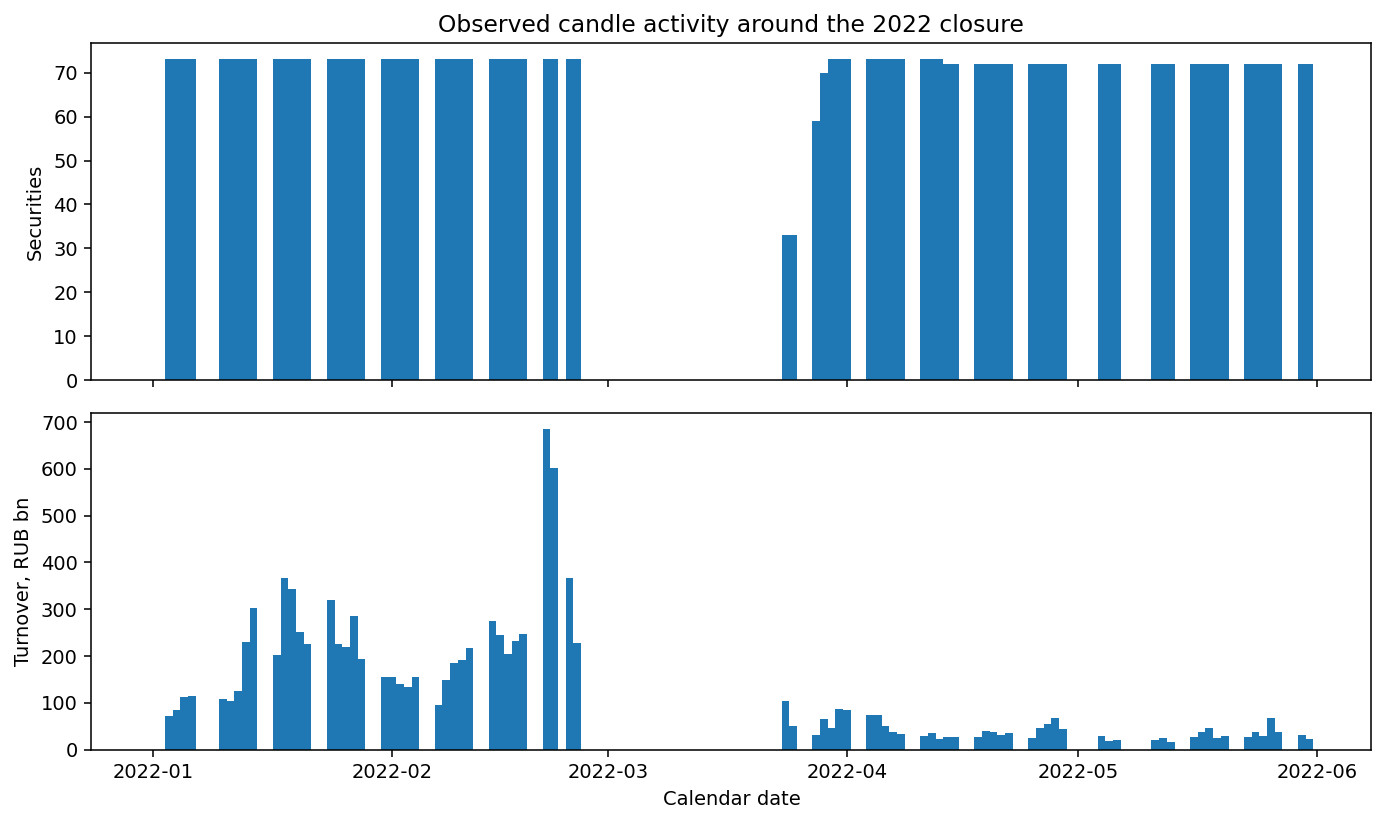

In [3]:
display(Image(filename=str(ROOT / "reports/eda/figures/activity_2022.png")))

## Диагностические таргеты 5 и 20 сессий

Используются open(t+1+h)/open(t+1) и единый наблюдаемый календарь. На графике отдельно убраны интервалы с raw-скачком более 50%, распределение остальных значений обрезано только для отображения; сводная таблица сохраняет исходные экстремумы. Это доходности цен в том виде, в каком их ретроспективно отдаёт ISS; источник может менять масштаб истории. Поправки на корпоративные события и дивиденды независимо не проверены, total return не установлен.

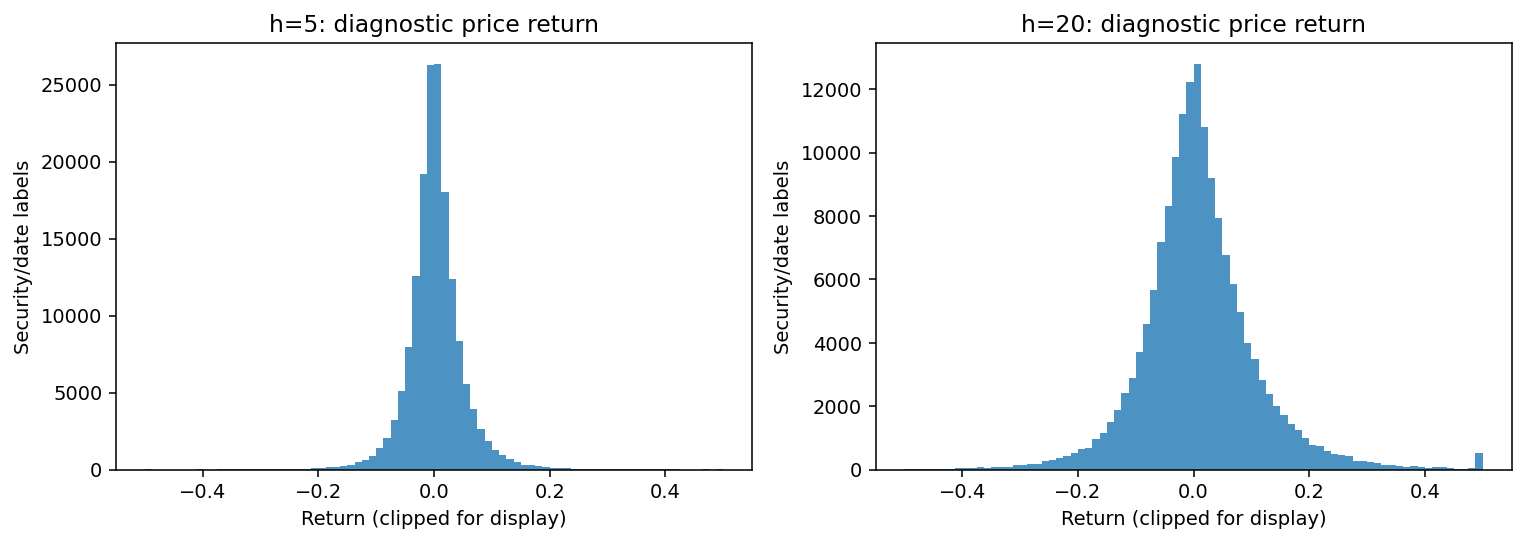

,count,mean,std,min,p01,median,p99,max,horizon,grid_rows,available_share,missing_price_grid_rows,calendar_gap_grid_rows,large_jump_grid_rows,clean_count,clean_values_clipped_for_display
0,165642,0.002505,0.052730,-0.553249,-0.135568,0.000250,0.156285,1.819324,5,223212,0.742084,57372,534,30,165620,57
1,162819,0.010082,0.105082,-0.564854,-0.248314,0.002929,0.326745,1.986694,20,223212,0.729437,59700,1869,105,162754,497


In [4]:
display(Image(filename=str(ROOT / "reports/eda/figures/price_targets.png")))
display(pd.read_csv(ROOT / "reports/eda/target_summary.csv").head(15))

## Рыночные режимы

Общий пул наблюдений меняется вместе с составом панели; различия распределений не являются статистическим доказательством изменения предсказуемости. Для оценки моделей нужны временные срезы и одинаковый point-in-time универсум.

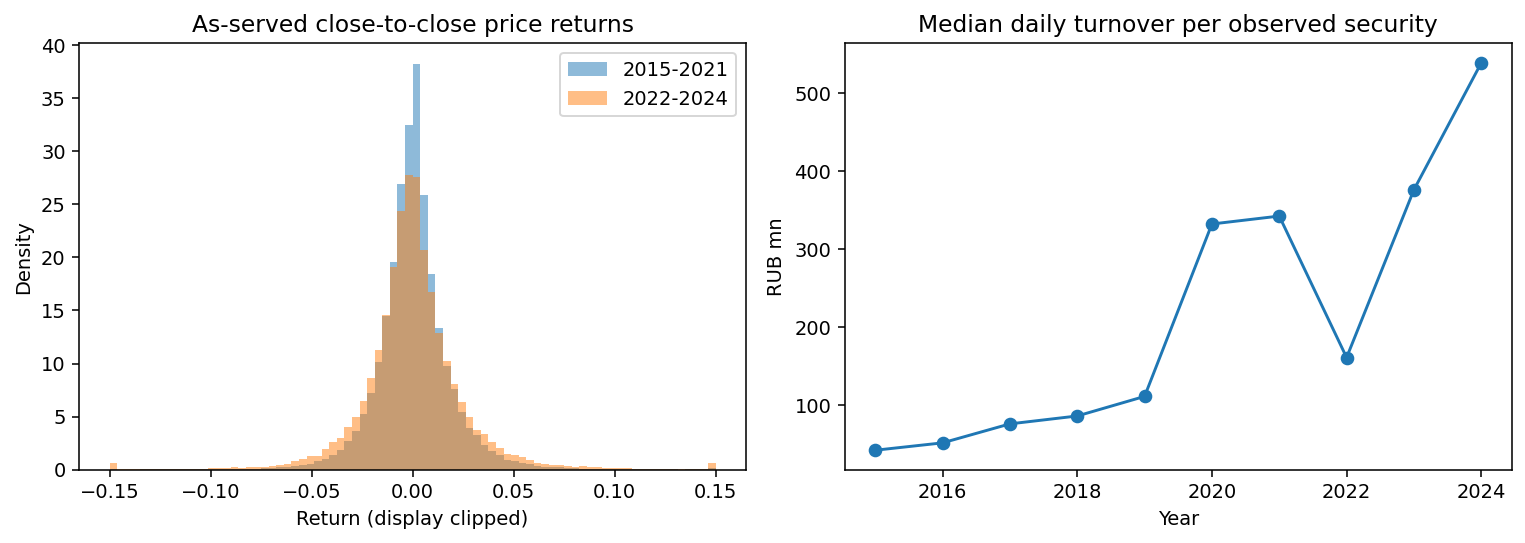

,count,mean,std,min,p01,median,p99,max,regime,abs_return_gt_50pct,values_clipped_for_display,median_20d_volatility,median_daily_turnover_rub
0,113953,0.000661,0.020069,-0.369224,-0.049688,0.000000,0.057227,0.998062,2015-2021,3,115,0.015186,125456470.0
1,52586,0.000054,0.029288,-0.769841,-0.074191,-0.000621,0.082313,0.450980,2022-2024,1,227,0.019570,335505460.0


In [5]:
display(Image(filename=str(ROOT / "reports/eda/figures/regime_returns.png")))
display(pd.read_csv(ROOT / "reports/eda/regime_summary.csv").head(15))

## Совместное движение бумаг

Корреляция рассчитана без заполнения пропусков и при наличии минимум 252 общих наблюдений. Разные попарные окна не дают гарантию PSD; для портфельной ковариации потребуется общая матрица и shrinkage.

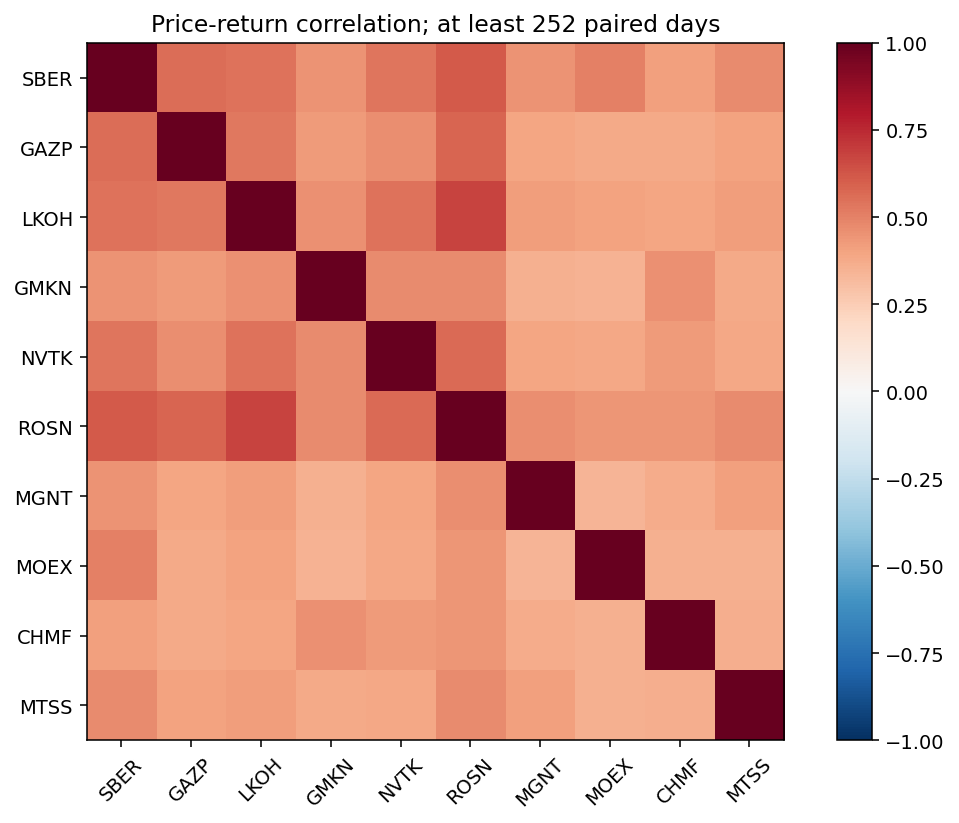

,secid,SBER,GAZP,LKOH,GMKN,NVTK,ROSN,MGNT,MOEX,CHMF,MTSS
0,SBER,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
1,GAZP,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
2,LKOH,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
3,GMKN,2501,2501,2501,2501,2501,2501,2501,2501,2501,2501
4,NVTK,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
5,ROSN,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
6,MGNT,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
7,MOEX,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
8,CHMF,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506
9,MTSS,2506,2506,2506,2501,2506,2506,2506,2506,2506,2506


In [6]:
display(Image(filename=str(ROOT / "reports/eda/figures/correlation.png")))
display(pd.read_csv(ROOT / "reports/eda/correlation_overlap.csv").head(15))

## Новостные данные

Фактически загружено 91,477 строк за 2015-09-01–2024-12-16. Повторных нормализованных текстов 1,711. Время публикации не задано у 74,040 строк. Такие статьи нельзя привязывать к закрытию торгов по выдуманному времени суток; нужна консервативная задержка либо исключение из строгой PIT-абляции. Крупнейшая группа источник/день содержит 4,417 статей (bcs_tech, 2021-02-19); это аномалия, требующая проверки происхождения дат. Поставляемые train/test объединены только для описательной EDA; обучение потребует собственного временного разбиения с группировкой дубликатов. Покрытие новостями ограничивает период абляции.

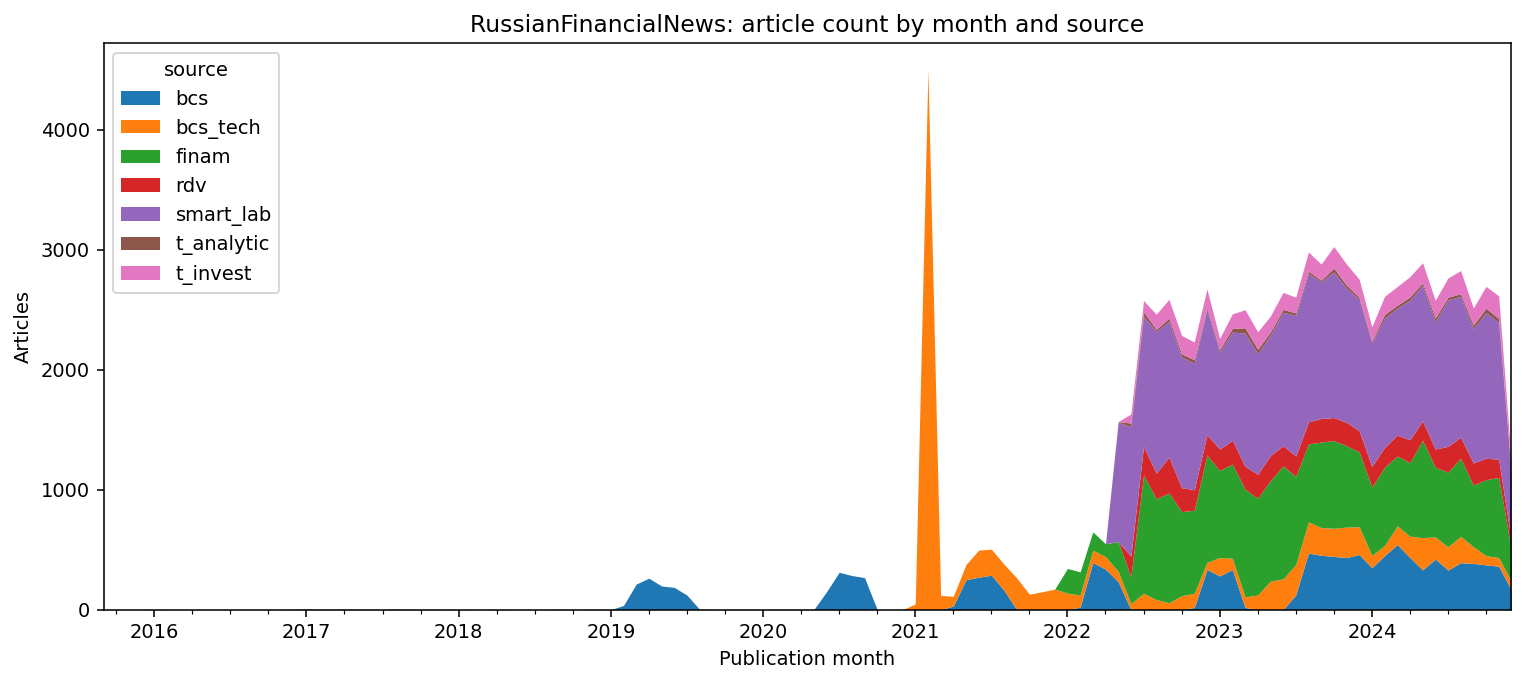

In [7]:
display(Image(filename=str(ROOT / "reports/eda/figures/news_monthly.png")))

## Покрытие компаний новостями

Применены регулярные выражения к заголовкам, текстам и tags после удаления точных нормализованных дубликатов. Это слабая привязка к компании: совпадение не означает тональность по конкретной бумаге. Знаменатель — пересечение диапазона новостей, истории компании и дат MCFTR; время суток пока не учтено.

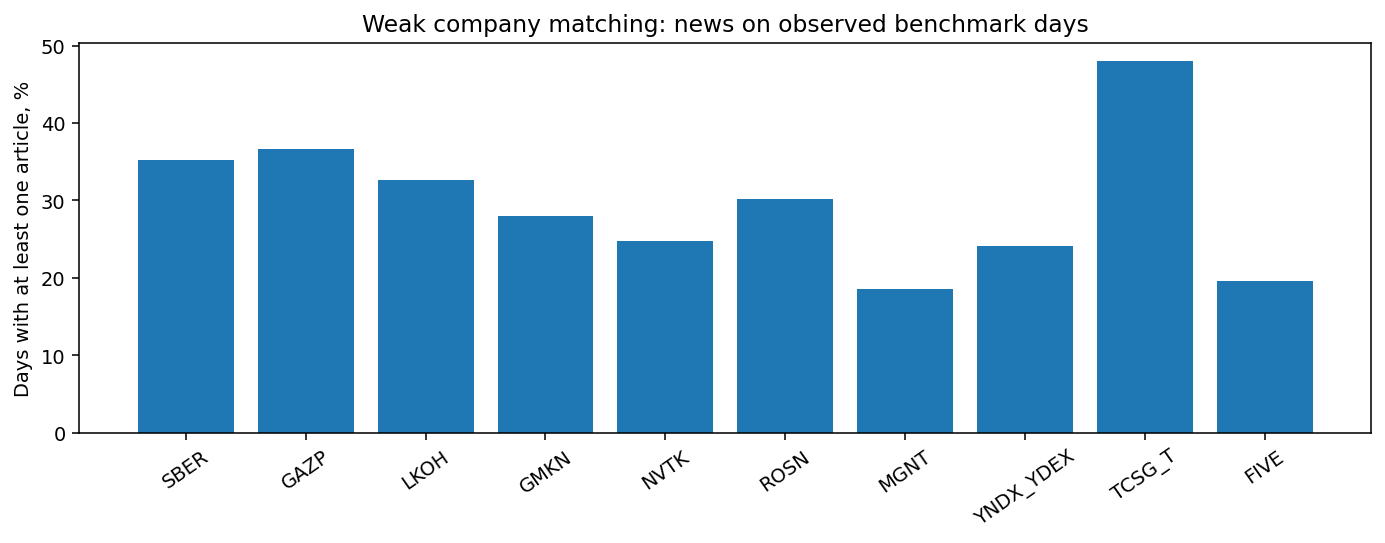

,entity,matched_distinct_articles,overlap_start,overlap_end,overlap_calendar_days,overlap_benchmark_days,calendar_days_with_news,benchmark_days_with_news,benchmark_day_coverage
0,SBER,3678,2015-09-01,2024-12-16,3395,2333,947,822,0.352336
1,GAZP,4858,2015-09-01,2024-12-16,3395,2333,1033,856,0.366910
2,LKOH,2866,2015-09-01,2024-12-16,3395,2333,883,761,0.326189
3,GMKN,2063,2015-09-01,2024-12-16,3395,2333,751,653,0.279897
4,NVTK,1739,2015-09-01,2024-12-16,3395,2333,651,577,0.247321
5,ROSN,2246,2015-09-01,2024-12-16,3395,2333,809,703,0.301329
6,MGNT,1037,2015-09-01,2024-12-16,3395,2333,470,433,0.185598
7,YNDX_YDEX,1879,2015-09-01,2024-12-16,3395,2333,656,562,0.240892
8,TCSG_T,2567,2019-10-28,2024-12-16,1877,1282,711,615,0.479719
9,FIVE,914,2018-02-01,2024-04-03,2254,1542,339,302,0.195850


In [8]:
display(Image(filename=str(ROOT / "reports/eda/figures/news_coverage.png")))
display(pd.read_csv(ROOT / "reports/eda/news_entity_coverage.csv").head(15))

## Макроисточники

Дата действия ставки/официального курса отличается от времени публикации. Предполагаемый backward as-of join должен использовать проверенный available_at; обратное заполнение и интерполяция из будущего запрещены.

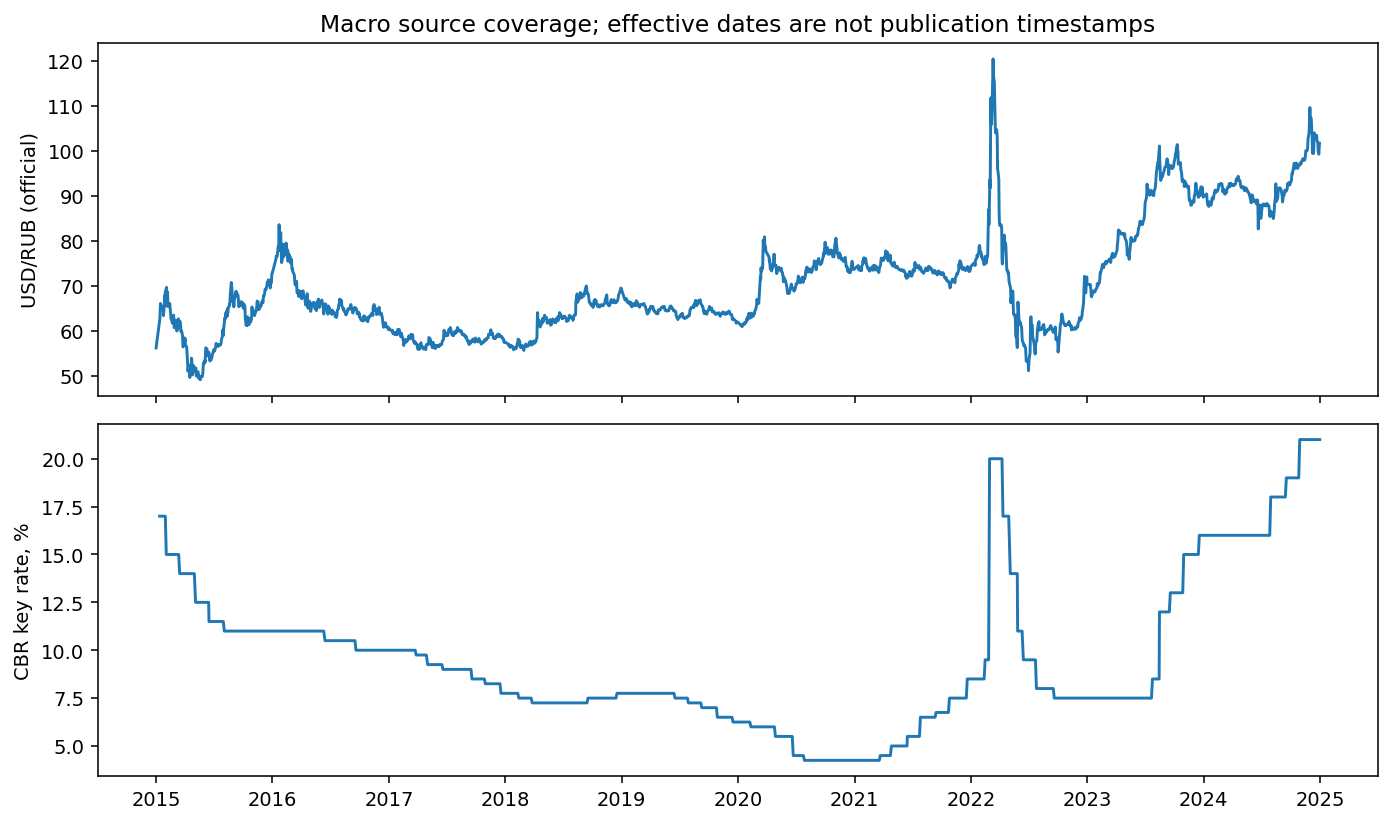

In [9]:
display(Image(filename=str(ROOT / "reports/eda/figures/macro.png")))

## Ограничения и следующие шаги

1. Восстановить ежедневные интервалы состава индекса, корпоративные события и проверенный календарь.
2. Проверить исторический момент доступности данных и часовой пояс новостей.
3. Подготовить total-return метки и вложенную временную валидацию с purge по label_end_time.
4. Сначала проверить ценовой baseline; сентимент сравнивать на том же периоде и универсуме.
5. Holdout 2025–2026 открыть один раз после фиксации модели и правил исполнения.